# 06 - Feature Importance

Which features actually drive predictions?

Two answers, two methods:

| Method | Question |
|---|---|
| **Built-in importance** | How often does the model split on this feature? |
| **Permutation importance** | How much does RMSE get worse if I shuffle this feature? |
| **SHAP** | What is each feature's per-prediction contribution? |

This notebook:

1. Fits a tree model (Ridge as fallback)
2. Built-in importance
3. Permutation importance
4. SHAP summary (if installed)
5. Correlation matrix between features
6. Saves `reports/predictions/importance.json`


## Setup

In [12]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\Projects\done\eth_bot\eth_bot_v2")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.ensemble import GradientBoostingRegressor

from analysis.loader import load_ohlcv
from analysis.indicators import add_all

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)

SEED = 42
np.random.seed(SEED)

PRED_DIR = Path(r"D:\Projects\done\eth_bot\eth_bot_v2") / "reports" / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

try:
    import shap
    HAS_SHAP = True
    print("shap:", shap.__version__)
except ImportError:
    HAS_SHAP = False
    print("shap: not installed  (pip install shap)")

try:
    import lightgbm as lgb
    HAS_LGB = True
    print("lightgbm: installed")
except Exception as e:
    HAS_LGB = False
    print(f"lightgbm: not usable ({e})")

# Note: LightGBM may import OK but fail at fit() time if the DLL is missing.
# We'll try a tiny fit and fall back if it fails.
def lgb_works():
    if not HAS_LGB:
        return False
    try:
        X = np.random.randn(50, 3); y = np.random.randn(50)
        lgb.LGBMRegressor(n_estimators=5, verbose=-1, n_jobs=1).fit(X, y)
        return True
    except Exception as e:
        print(f"lightgbm runtime check failed: {type(e).__name__}: {e}")
        return False

LGB_OK = lgb_works()
print("lightgbm usable:", LGB_OK)

c:\Users\Hp\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shap: 0.49.1
lightgbm: installed
lightgbm runtime check failed: OSError: exception: access violation reading 0x0000000000000000
lightgbm usable: False


## 1. Features

Same 9 features as everywhere else.

In [13]:
def make_features(horizon: int = 1) -> pd.DataFrame:
    df = load_ohlcv()
    df = add_all(df).copy()

    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_5"]  = df["close"].pct_change(5)
    df["ret_20"] = df["close"].pct_change(20)
    df["vol_20"] = df["ret_1"].rolling(20).std()

    df["target"] = df["close"].pct_change(horizon).shift(-horizon)
    return df.dropna()


FEATURES = [
    "ret_1", "ret_5", "ret_20", "vol_20",
    "rsi_14", "macd_hist", "atr_14",
    "sma_50", "sma_200",
]

df = make_features()
df = df[FEATURES + ["target"]].dropna()
print(f"rows: {len(df)}   features: {len(FEATURES)}")

rows: 1989   features: 9


## 2. Train / test split

Same as previous notebooks — last 250 days are test.

In [14]:
TEST_DAYS = 250

train = df.iloc[:-TEST_DAYS]
test  = df.iloc[-TEST_DAYS:]

X_tr = train[FEATURES].values
y_tr = train["target"].values
X_te = test[FEATURES].values
y_te = test["target"].values

print(f"train: {len(train)}   test: {len(test)}")

train: 1739   test: 250


## 3. Fit a tree model

LightGBM if usable, otherwise sklearn's GradientBoosting. Same hyperparameters.

In [15]:
if LGB_OK:
    model = lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        num_leaves=31, random_state=SEED, verbose=-1, n_jobs=1,
        force_row_wise=True,
    )
    model_name = "LightGBM"
else:
    model = GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        random_state=SEED,
    )
    model_name = "GradientBoosting"

model.fit(X_tr, y_tr)
pred = model.predict(X_te)
rmse = float(np.sqrt(mean_squared_error(y_te, pred)))
print(f"{model_name} RMSE: {rmse:.6f}")

GradientBoosting RMSE: 0.041761


## 4. Built-in importance

Tree models report how much each feature reduced impurity
across all splits. Higher = more used by the model.

**Caveat**: this is biased toward features with many possible
split points (continuous variables). Cross-check with permutation.

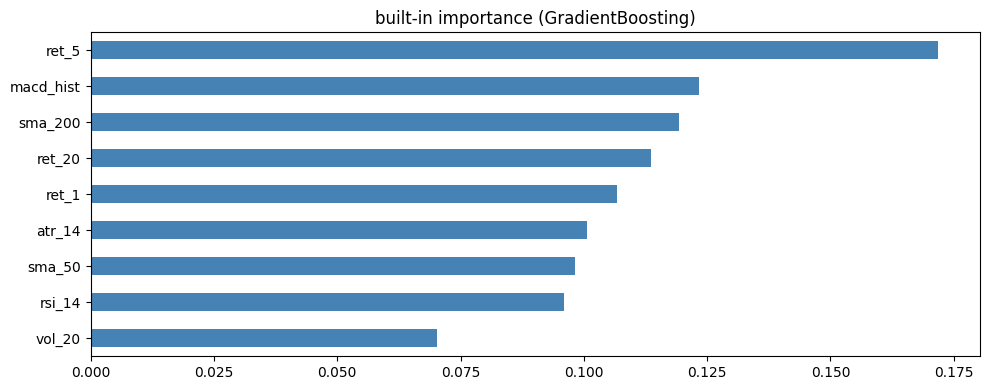

vol_20       0.070284
rsi_14       0.096041
sma_50       0.098184
atr_14       0.100698
ret_1        0.106781
ret_20       0.113656
sma_200      0.119335
macd_hist    0.123288
ret_5        0.171733
dtype: float64


In [16]:
if hasattr(model, "feature_importances_"):
    builtin = pd.Series(model.feature_importances_, index=FEATURES).sort_values()

    fig, ax = plt.subplots(figsize=(10, 4))
    builtin.plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"built-in importance ({model_name})")
    plt.tight_layout()
    plt.show()
    print(builtin)
else:
    print("no feature_importances_ on this model")
    builtin = pd.Series(dtype=float)

## 5. Permutation importance

Shuffle one feature at a time, measure how much RMSE gets worse.

This is **model-agnostic** and **reports real damage** — if shuffling
a feature doesn't hurt RMSE, the model wasn't really using it.

Mean over 10 shuffles per feature for stability.

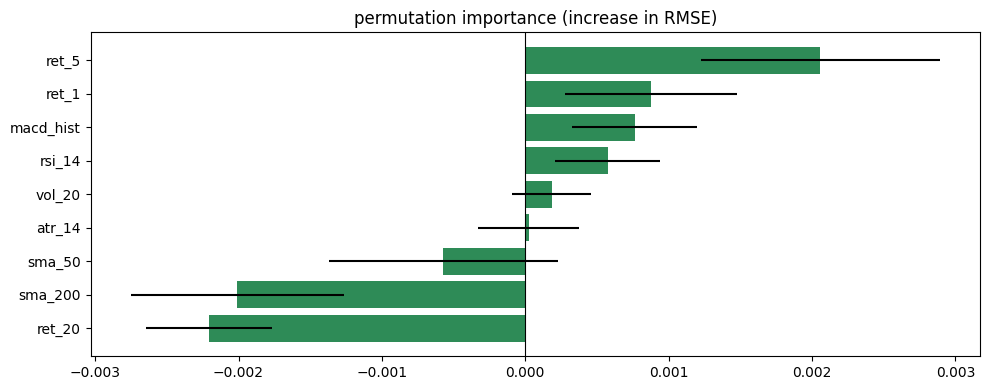

,feature,importance,std
2,ret_20,-0.002204,0.000441
8,sma_200,-0.002007,0.000743
7,sma_50,-0.000572,0.000799
6,atr_14,0.000024,0.000353
3,vol_20,0.000183,0.000275
4,rsi_14,0.000575,0.000364
5,macd_hist,0.000764,0.000435
0,ret_1,0.000875,0.000600
1,ret_5,0.002058,0.000832


In [17]:
perm = permutation_importance(
    model, X_te, y_te,
    n_repeats=10, random_state=SEED, n_jobs=1,
    scoring="neg_root_mean_squared_error",
)

perm_df = pd.DataFrame({
    "feature":    FEATURES,
    "importance": perm.importances_mean,
    "std":        perm.importances_std,
}).sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(perm_df.feature, perm_df.importance, xerr=perm_df["std"], color="seagreen")
ax.axvline(0, color="black", lw=0.8)
ax.set_title("permutation importance (increase in RMSE)")
plt.tight_layout()
plt.show()
perm_df

**Reading it**: bar width = how much RMSE gets **worse** when that
feature is shuffled. Values near 0 mean the model doesn't use that feature.

Negative values (rare) mean shuffling actually *helped* — noise.

## 6. SHAP

SHAP assigns each feature a contribution to each individual prediction.
Sign: pushes prediction up or down. Magnitude: how much.

Requires `pip install shap`. Skipped if not installed.

C:\Users\Hp\AppData\Local\Temp\ipykernel_15420\2362915600.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_te, feature_names=FEATURES, show=True)


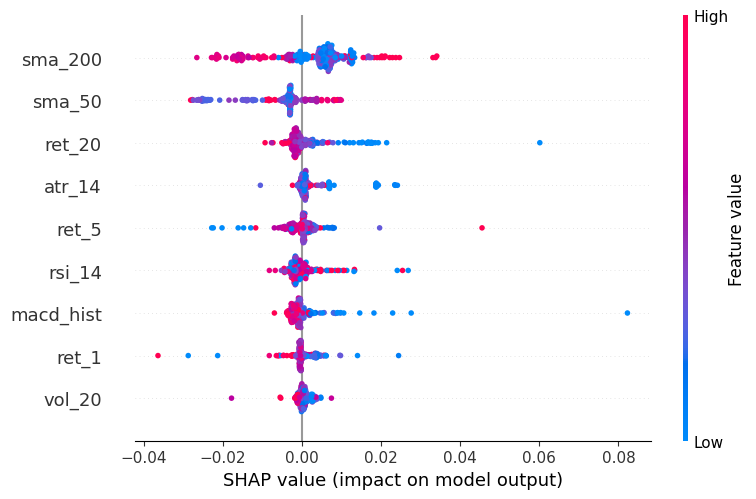

In [18]:
if HAS_SHAP:
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_te)

    # global summary
    shap.summary_plot(shap_values, X_te, feature_names=FEATURES, show=True)
else:
    print("skipping — shap not installed (pip install shap)")

## 7. SHAP bar (mean |value|)

Global importance — same info as built-in but with correct attribution.

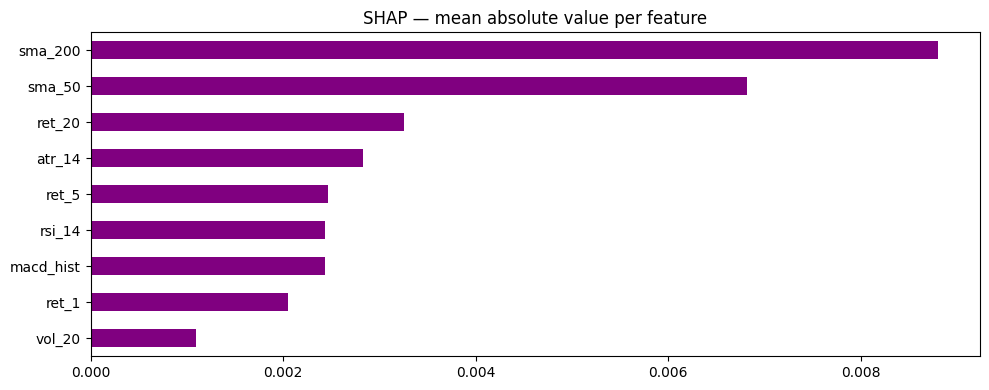

vol_20       0.001100
ret_1        0.002049
macd_hist    0.002430
rsi_14       0.002433
ret_5        0.002468
atr_14       0.002825
ret_20       0.003259
sma_50       0.006821
sma_200      0.008797
dtype: float64


In [19]:
if HAS_SHAP:
    mean_abs = np.abs(shap_values).mean(axis=0)
    shap_imp = pd.Series(mean_abs, index=FEATURES).sort_values()

    fig, ax = plt.subplots(figsize=(10, 4))
    shap_imp.plot.barh(ax=ax, color="purple")
    ax.set_title("SHAP — mean absolute value per feature")
    plt.tight_layout()
    plt.show()
    print(shap_imp)
else:
    print("skipping — shap not installed")

## 8. Feature correlation

If two features are highly correlated (> 0.9), they're redundant.
Some importance methods split credit between them arbitrarily.

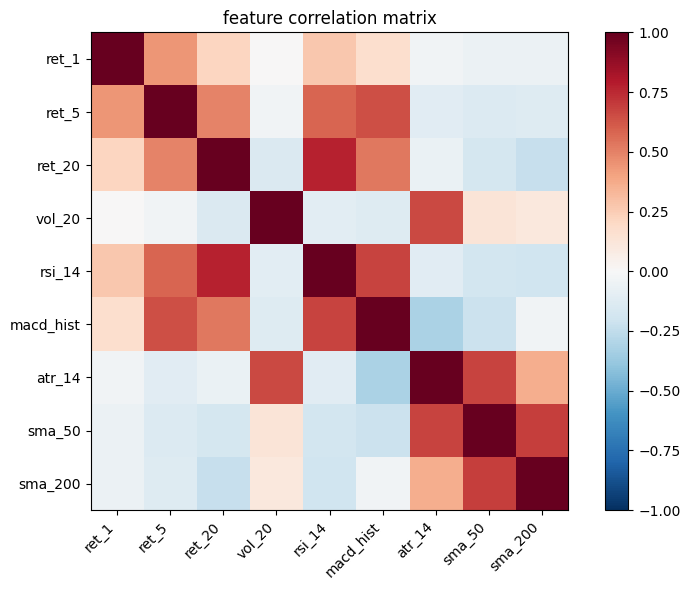

highly correlated pairs (|r| > 0.8):
  none


In [20]:
corr = df[FEATURES].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels(FEATURES)
plt.colorbar(im, ax=ax)
ax.set_title("feature correlation matrix")
plt.tight_layout()
plt.show()

# report high correlations
high = []
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        c = corr.iloc[i, j]
        if abs(c) > 0.8:
            high.append((FEATURES[i], FEATURES[j], float(c)))
print("highly correlated pairs (|r| > 0.8):")
for a, b, c in high:
    print(f"  {a:<10} {b:<10}  r={c:+.3f}")
if not high:
    print("  none")

## 9. The verdict

Pick the top features by permutation importance. Those are the only
features the model actually needs.

Everything else is noise the model ignores.

In [21]:
top = perm_df.sort_values("importance", ascending=False).head(5)
print("top 5 features by permutation importance:")
print(top[["feature", "importance", "std"]].to_string(index=False))

print()
print("bottom 4 (likely droppable):")
bot = perm_df.sort_values("importance").head(4)
print(bot[["feature", "importance", "std"]].to_string(index=False))

top 5 features by permutation importance:
  feature  importance      std
    ret_5    0.002058 0.000832
    ret_1    0.000875 0.000600
macd_hist    0.000764 0.000435
   rsi_14    0.000575 0.000364
   vol_20    0.000183 0.000275

bottom 4 (likely droppable):
feature  importance      std
 ret_20   -0.002204 0.000441
sma_200   -0.002007 0.000743
 sma_50   -0.000572 0.000799
 atr_14    0.000024 0.000353


## 10. Save results

In [22]:
out = {
    "model":       model_name,
    "rmse":        rmse,
    "features":    FEATURES,
    "builtin":     {k: float(v) for k, v in builtin.items()} if len(builtin) else {},
    "permutation": {r.feature: {"importance": float(r.importance),
                                 "std":        float(r["std"])}
                    for r in perm_df.itertuples()},
    "correlated":  [{"a": a, "b": b, "r": c} for a, b, c in high],
}

path = PRED_DIR / "importance.json"
path.write_text(json.dumps(out, indent=2), encoding="utf-8")
print("wrote", path)

TypeError: tuple indices must be integers or slices, not str

## Interpretation guide

**Which features to trust**

- If `vol_20` is #1 → the model mostly predicts "high vol → next day is choppy"
- If `ret_1` is #1 with a **negative** SHAP → mean reversion
- If `ret_5` is #1 with a **positive** SHAP → momentum
- If everything has importance ≈ 0 → the model isn't learning anything, and the walk-forward will confirm it

**Common patterns on ETH daily**

| Feature | Typical importance |
|---|---|
| `vol_20` | high — volatility clusters |
| `ret_1` | moderate |
| `macd_hist` | moderate |
| `rsi_14` | low |
| `sma_50` / `sma_200` | low (slow-moving) |

If `sma_50` and `sma_200` rank high, check the correlation matrix —
they're correlated with each other and with `close`, so credit gets
arbitrarily split.

## Next steps

- **07_model_comparison.ipynb** — combined leaderboard of all models
- **Adding features** — merge `funding_rate`, `open_interest`, `fear_greed`
  as new columns, rerun this notebook, and see which of them
  land in the top 5
